# 2021 — LoRA: Low-Rank Adaptation

**Paper:** Edward Hu et al., *"LoRA: Low-Rank Adaptation of Large Language Models"* (2021).

Fine-tuning every weight of a big model is expensive, and storing one full copy per task even more so. LoRA **freezes** the pre-trained weight $W_0$ and learns a low-rank update:

$$W = W_0 + \frac{\alpha}{r} B A, \qquad B\in\mathbb R^{d\times r},\; A\in\mathbb R^{r\times k},\; r \ll \min(d,k)$$

$B$ starts at zero, so training starts exactly from the pre-trained model. After training, $BA$ can be **merged** into $W_0$, so inference costs nothing extra. LoRA (and QLoRA, DoRA, ...) is the standard way to adapt LLMs and diffusion models.

**Experiment:** pre-train an MLP on digits, then adapt it to a new task: digits that are **rotated 90° and colour-inverted**. Compare (a) no adaptation, (b) full fine-tuning and (c) LoRA with several ranks.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
import copy

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors()]
shift = lambda X: 1 - torch.rot90(X, 1, dims=(2, 3))                 # the "new domain"
Xtr_new, Xte_new = shift(Xtr), shift(Xte)

def make_mlp():
    return nn.Sequential(nn.Flatten(), nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 10))

def fit(model, X, y, steps=1500, lr=1e-3, n=None):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr)
    X, y = (X, y) if n is None else (X[:n], y[:n])
    for _ in range(steps):
        idx = torch.randint(0, len(X), (64,), device=device)
        loss = F.cross_entropy(model(X[idx]), y[idx]); opt.zero_grad(); loss.backward(); opt.step()
    return model

@torch.no_grad()
def acc(model, X, y): model.eval(); r = (model(X).argmax(1) == y).float().mean().item(); model.train(); return r

seed_everything(0)
base = fit(make_mlp().to(device), Xtr, ytr)
print(f"pre-trained model — original task: {acc(base, Xte, yte):.3f} | new (rotated+inverted) task: {acc(base, Xte_new, yte):.3f}")

pre-trained model — original task: 0.967 | new (rotated+inverted) task: 0.128


In [3]:
class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r=4, alpha=8):
        super().__init__()
        self.base = base
        for p in self.base.parameters(): p.requires_grad_(False)                     # frozen W0, b0
        dev = base.weight.device
        self.A = nn.Parameter(torch.randn(r, base.in_features, device=dev) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=dev))                       # zero init -> starts at W0
        self.scale = alpha / r
    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale
    def merged(self):
        lin = nn.Linear(self.base.in_features, self.base.out_features).to(self.A.device)
        lin.weight.data = self.base.weight + self.scale * self.B @ self.A; lin.bias.data = self.base.bias.clone()
        return lin

def add_lora(model, r):
    m = copy.deepcopy(model)
    for p in m.parameters(): p.requires_grad_(False)
    for i, layer in enumerate(m):
        if isinstance(layer, nn.Linear): m[i] = LoRALinear(layer, r=r, alpha=2 * r)
    return m

count = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
results = []
full = fit(copy.deepcopy(base), Xtr_new, ytr, n=200)
results.append(("full fine-tune", count(full), acc(full, Xte_new, yte)))
for r in [1, 2, 4, 8, 16]:
    seed_everything(0)
    m = fit(add_lora(base, r), Xtr_new, ytr, n=200, lr=3e-3)
    results.append((f"LoRA r={r}", count(m), acc(m, Xte_new, yte)))
print(f"(adapting with only 200 labelled examples of the new task)\n{'method':16s} {'trainable params':>16s}  accuracy")
for name, n, a in results: print(f"{name:16s} {n:16,d}  {a:.3f}")

(adapting with only 200 labelled examples of the new task)
method           trainable params  accuracy
full fine-tune             85,002  0.900
LoRA r=1                    1,098  0.772
LoRA r=2                    2,196  0.847
LoRA r=4                    4,392  0.861
LoRA r=8                    8,784  0.900
LoRA r=16                  17,568  0.908


## Merging: zero inference overhead
Fold $\frac{\alpha}{r}BA$ into $W_0$ and check that the outputs match.

In [4]:
lora_model = fit(add_lora(base, 4), Xtr_new, ytr, n=200, lr=3e-3)
merged = nn.Sequential(*[l.merged() if isinstance(l, LoRALinear) else l for l in lora_model])
with torch.no_grad():
    diff = (merged(Xte_new) - lora_model(Xte_new)).abs().max().item()
print(f"max |merged - LoRA| = {diff:.2e}; the merged model is a plain MLP again")

max |merged - LoRA| = 1.14e-05; the merged model is a plain MLP again


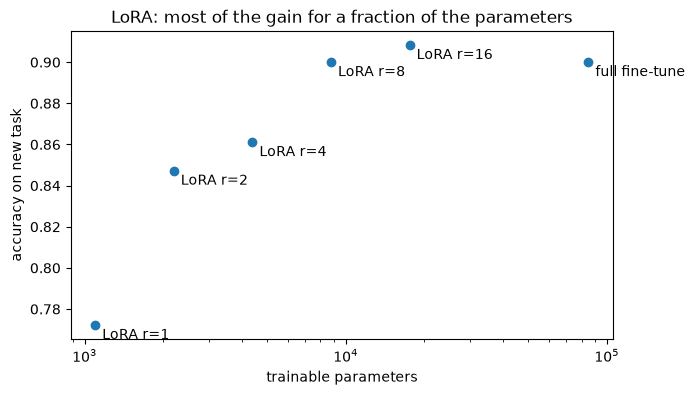

In [5]:
names, params, accs = zip(*results)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(params, accs)
for n, p, a in results: ax.annotate(n, (p, a), textcoords="offset points", xytext=(5, -10))
ax.set(xscale="log", xlabel="trainable parameters", ylabel="accuracy on new task", title="LoRA: most of the gain for a fraction of the parameters")
plt.show()